## 0. Setup

`Lab Assignment: Landmark Recognition Using the SIFT Algorithm`



In [1]:
import os, time, pickle, zipfile, shutil, glob
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
assert hasattr(cv2, "SIFT_create"), "Please upgrade: pip install -U opencv-python"


DB_DIR = "landmark_db"
OUT_DIR = "results"
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
MAX_DIM = 1000
N_FEATURES = 5000
RATIO = 0.75
MIN_GOOD_MATCHES = 15
MIN_INLIERS = 10
MIN_INLIER_RATIO = 0.25
RANSAC_THRESH = 5.0
MARGIN = 1.2
TOP_N_VERIFY = 3
os.makedirs(OUT_DIR, exist_ok=True)

OpenCV version: 4.14.0


## Task 1: Landmark Image Database
Create a folder structure like this (at least **5 landmarks**, several photos each, different angles/distances):
```
landmark_db/
   Eiffel Tower/   img1.jpg img2.jpg ...
   Taj Mahal/
   Great Wall of China/
   Statue of Liberty/
   Colosseum/
test_queries/      (photos NOT in landmark_db, used for testing)
```
**Easiest way:** put those two folders in one ZIP file named `data.zip` (containing `landmark_db/` and `test_queries/`) and choose option `"upload"` below. Or keep the ZIP in Google Drive and use `"drive"`.

### Option A (recommended): download the dataset automatically
The next cell downloads freely licensed photos from **Wikimedia Commons**: 6 reference photos for each of 5 landmarks (Eiffel Tower, Taj Mahal, Great Wall of China, Statue of Liberty, Colosseum), 2 held-out test photos per landmark, and 2 photos of the **Pyramids of Giza** as the "landmark not in database" test. Credits are saved in `dataset_credits.csv`. Requires internet (Colab has it); takes about 2-4 minutes.

In [2]:
"""
Automatic landmark dataset builder (run inside Google Colab or any PC with internet).
Downloads freely licensed photos from Wikimedia Commons and creates:

    landmark_db/<Landmark>/<Landmark>_1.jpg ...   (reference images, Task 1)
    test_queries/<Landmark>_1.jpg ...             (held-out photos NOT in the database)
    test_queries/unknown_<Name>_1.jpg             (landmark NOT in the database)
    dataset_credits.csv                           (title + source URL of every image)
"""
import csv
import io
import os
import shutil
import time

import requests
from PIL import Image

LANDMARKS = {
    "Eiffel Tower": "Eiffel Tower Paris",
    "Taj Mahal": "Taj Mahal Agra",
    "Great Wall of China": "Great Wall of China",
    "Statue of Liberty": "Statue of Liberty New York",
    "Colosseum": "Colosseum Rome",
}
UNKNOWN = {"Pyramids of Giza": "Great Pyramid of Giza"}
N_DB = 6          # reference images per landmark
N_TEST = 2        # held-out test photos per landmark
N_UNKNOWN = 2

API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "LandmarkLab/1.0 (university lab assignment; python-requests)"}
BAD_WORDS = ("map", "logo", "flag", "icon", "stamp", "coin", "poster", "drawing", "painting",
             "model", "lego", "replica", "interior", "inside", "panorama", "diagram",
             "sketch", "postcard", "plan", "engraving", "illustration", "miniature")


def _get(url, **kw):
    for attempt in range(4):
        r = requests.get(url, headers=HEADERS, timeout=40, **kw)
        if r.status_code == 429:
            time.sleep(3 * (attempt + 1))
            continue
        r.raise_for_status()
        return r
    raise RuntimeError("Too many requests (HTTP 429). Wait a minute and run again.")


def search_images(query, limit=60):
    """Return [(title, thumb_url, page_url)] of suitable JPEG photos, best match first."""
    params = {
        "action": "query", "format": "json", "generator": "search",
        "gsrsearch": f"{query} filetype:bitmap", "gsrnamespace": 6, "gsrlimit": limit,
        "prop": "imageinfo", "iiprop": "url|mime|size", "iiurlwidth": 1000,
    }
    pages = _get(API, params=params).json().get("query", {}).get("pages", {})
    found = []
    for p in sorted(pages.values(), key=lambda x: x.get("index", 0)):
        info = (p.get("imageinfo") or [{}])[0]
        title = p.get("title", "")
        if info.get("mime") != "image/jpeg":
            continue
        if info.get("width", 0) < 1000 or info.get("height", 0) < 600:
            continue
        if any(w in title.lower() for w in BAD_WORDS):
            continue
        found.append((title, info.get("thumburl") or info.get("url"), info.get("descriptionurl", "")))
    return found


def _save_jpg(url, path):
    data = _get(url).content
    img = Image.open(io.BytesIO(data)).convert("RGB")
    img.save(path, "JPEG", quality=92)


def _fetch(name, query, n_first, n_second, dir_first, dir_second, prefix_second, credits):
    """First n_first images -> dir_first; next n_second images -> dir_second."""
    cands = search_images(query)
    if len(cands) < n_first + n_second:
        print(f"  WARNING: only {len(cands)} suitable images found for {name}")
    if dir_first:
        os.makedirs(dir_first, exist_ok=True)
    os.makedirs(dir_second, exist_ok=True)
    safe = name.replace(" ", "_")
    n1 = n2 = 0
    for title, url, page in cands:
        if n1 >= n_first and n2 >= n_second:
            break
        if n1 < n_first:
            path = os.path.join(dir_first, f"{safe}_{n1 + 1}.jpg")
        else:
            path = os.path.join(dir_second, f"{prefix_second}{safe}_{n2 + 1}.jpg")
        try:
            _save_jpg(url, path)
        except Exception as e:
            print("  skipped one image:", e)
            continue
        credits.append([path, title, page])
        if n1 < n_first:
            n1 += 1
        else:
            n2 += 1
        time.sleep(1.0)
    print(f"  {name:<22} database: {n1}   test: {n2}")


def download_dataset(db_dir="landmark_db", test_dir="test_queries"):
    for d in (db_dir, test_dir):
        shutil.rmtree(d, ignore_errors=True)
    os.makedirs(test_dir, exist_ok=True)
    credits = []
    for name, query in LANDMARKS.items():
        _fetch(name, query, N_DB, N_TEST, os.path.join(db_dir, name), test_dir, "", credits)
    for name, query in UNKNOWN.items():
        _fetch(name, query, 0, N_UNKNOWN, None, test_dir, "unknown_", credits)
    with open("dataset_credits.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["file", "Wikimedia Commons title", "source page (license/author)"])
        w.writerows(credits)
    print("\nDone. Folders created:", db_dir, "and", test_dir)
    print("Image credits saved in dataset_credits.csv (cite them in your report).")

In [3]:

DATA_SOURCE = "download"
DRIVE_ZIP_PATH = "/content/drive/MyDrive/data.zip"

def unzip(path):
    with zipfile.ZipFile(path) as z:
        z.extractall(".")
    print("Extracted:", path)

if DATA_SOURCE == "download":
    download_dataset()
elif DATA_SOURCE == "upload":
    from google.colab import files
    up = files.upload()
    for name in up:
        if name.lower().endswith(".zip"):
            unzip(name)
elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    unzip(DRIVE_ZIP_PATH)
else:
    print("Using folders already present in the Colab file browser.")

for lm in sorted(os.listdir(DB_DIR)):
    p = os.path.join(DB_DIR, lm)
    if os.path.isdir(p):
        n = len([f for f in os.listdir(p) if f.lower().endswith(IMG_EXT)])
        print(f"{lm:<25} {n} images")

  skipped one image: Too many requests (HTTP 429). Wait a minute and run again.
  Eiffel Tower           database: 6   test: 2
  Taj Mahal              database: 6   test: 2
  Great Wall of China    database: 6   test: 2
  Statue of Liberty      database: 6   test: 2
  Colosseum              database: 6   test: 2
  Pyramids of Giza       database: 0   test: 2

Done. Folders created: landmark_db and test_queries
Image credits saved in dataset_credits.csv (cite them in your report).
Colosseum                 6 images
Eiffel Tower              6 images
Great Wall of China       6 images
Statue of Liberty         6 images
Taj Mahal                 6 images


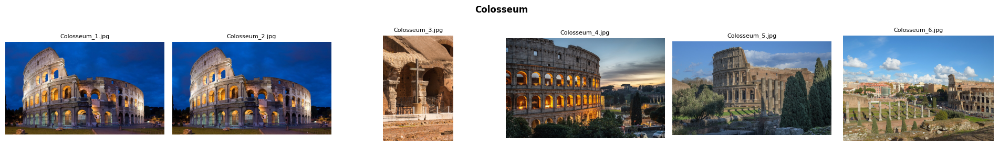

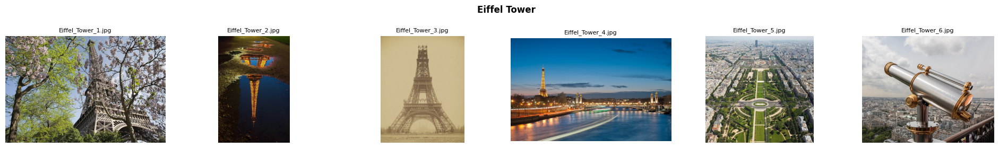

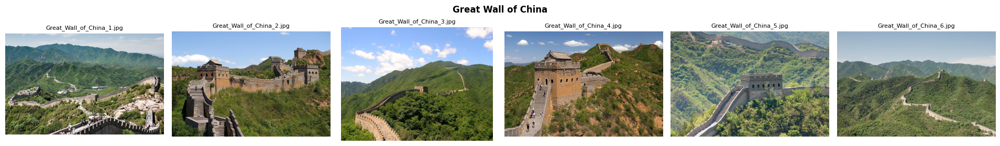

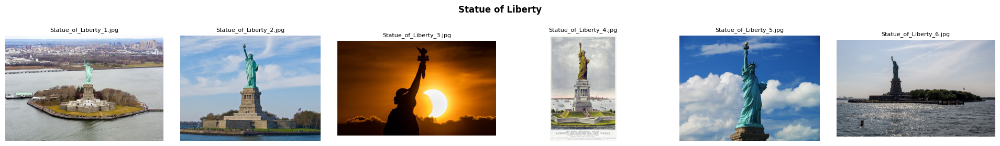

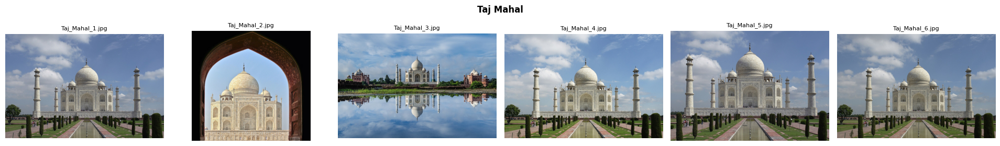

In [4]:

for lm in sorted(d for d in os.listdir(DB_DIR) if os.path.isdir(os.path.join(DB_DIR, d))):
    files_ = sorted(f for f in os.listdir(os.path.join(DB_DIR, lm)) if f.lower().endswith(IMG_EXT))
    fig, axes = plt.subplots(1, max(len(files_), 2), figsize=(3.2*max(len(files_), 2), 2.8))
    for ax in np.atleast_1d(axes): ax.axis("off")
    for ax, f in zip(np.atleast_1d(axes), files_):
        ax.imshow(cv2.cvtColor(cv2.imread(os.path.join(DB_DIR, lm, f)), cv2.COLOR_BGR2RGB)); ax.set_title(f, fontsize=8)
    fig.suptitle(lm, fontweight="bold"); plt.tight_layout(); plt.show()

### Download the landmark folder to your computer (deliverable)
This zips `landmark_db/`, `test_queries/` and `dataset_credits.csv` into `landmark_dataset.zip` and downloads it. Submit it as the organized landmark image database.

In [5]:
extras = ["dataset_credits.csv"] if os.path.exists("dataset_credits.csv") else []
os.makedirs("landmark_dataset", exist_ok=True)
for d_ in (DB_DIR, "test_queries"):
    if os.path.isdir(d_):
        shutil.copytree(d_, os.path.join("landmark_dataset", d_), dirs_exist_ok=True)
for e_ in extras:
    shutil.copy(e_, "landmark_dataset")
shutil.make_archive("landmark_dataset", "zip", "landmark_dataset")
try:
    from google.colab import files
    files.download("landmark_dataset.zip")
except ImportError:
    print("Saved landmark_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Helper functions
Image loading/resizing, SIFT extraction, keypoint (de)serialisation and display.

In [6]:
def prepare(img):
    h, w = img.shape[:2]
    s = MAX_DIM / max(h, w)
    if s < 1.0:
        img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
    return img

def load_image(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return prepare(img)

sift = cv2.SIFT_create(nfeatures=N_FEATURES)

def extract_sift(img_bgr):
    """Grayscale -> SIFT keypoints + 128-D descriptors."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return sift.detectAndCompute(gray, None)

def kp_to_tuple(k):
    return (k.pt[0], k.pt[1], k.size, k.angle, k.response, k.octave, k.class_id)

def tuple_to_kp(t):
    return cv2.KeyPoint(x=t[0], y=t[1], size=t[2], angle=t[3],
                        response=t[4], octave=int(t[5]), class_id=int(t[6]))

def draw_keypoints(img, kp):
    return cv2.drawKeypoints(img, kp, None, color=(0, 255, 0),
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

def show(img, title="", size=(9, 6), save=None):
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.tight_layout()
    if save:
        cv2.imwrite(os.path.join(OUT_DIR, save), img)
    plt.show()

## Task 2: SIFT Feature Extraction (reference images)
For every reference image: load → grayscale → detect SIFT keypoints → extract descriptors → display keypoints → store descriptors with the landmark label.

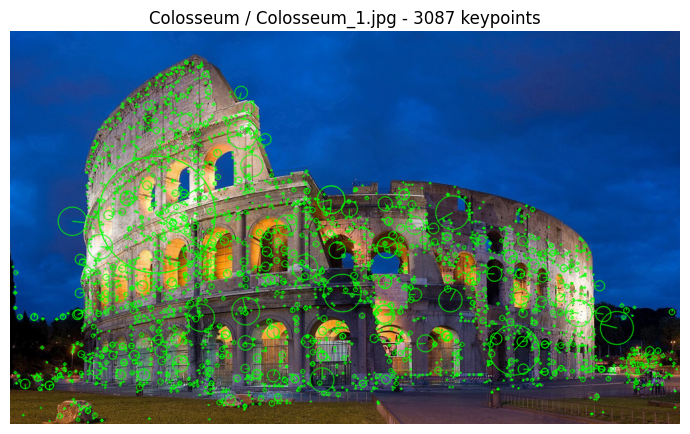

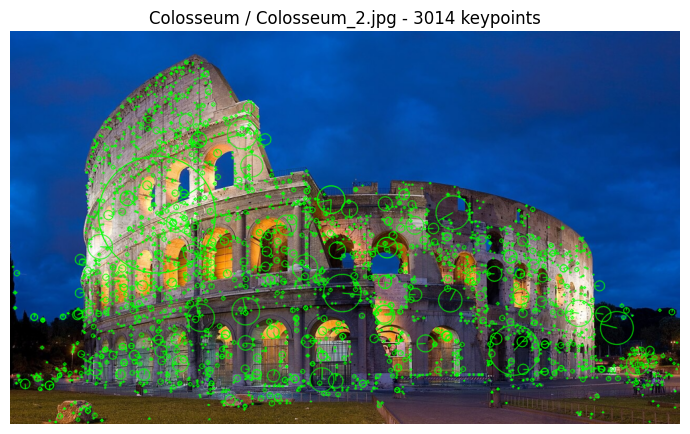

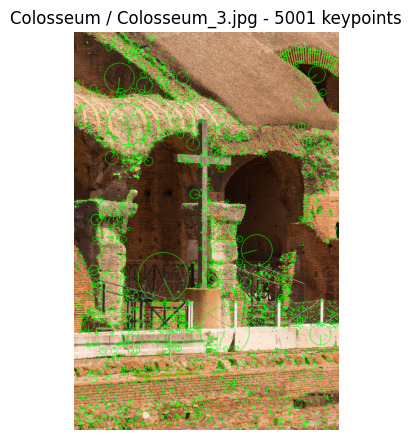

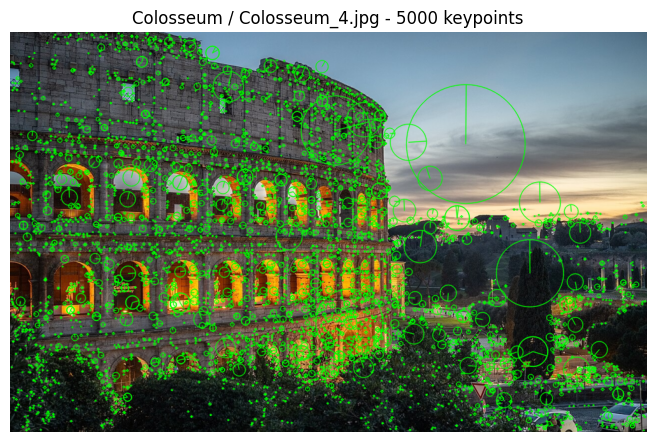

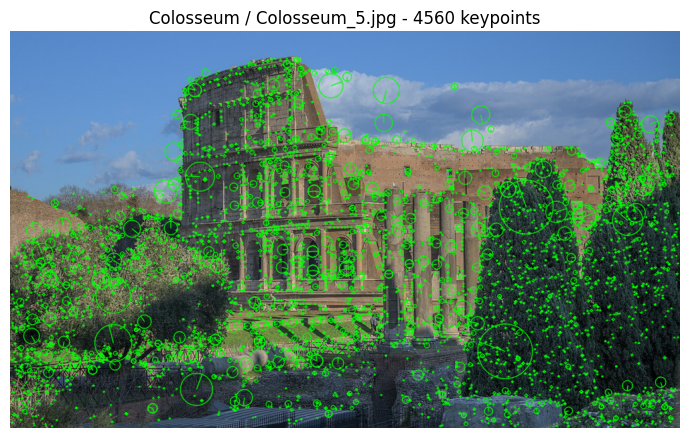

...

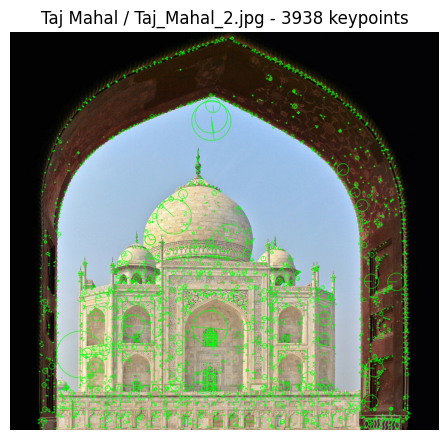

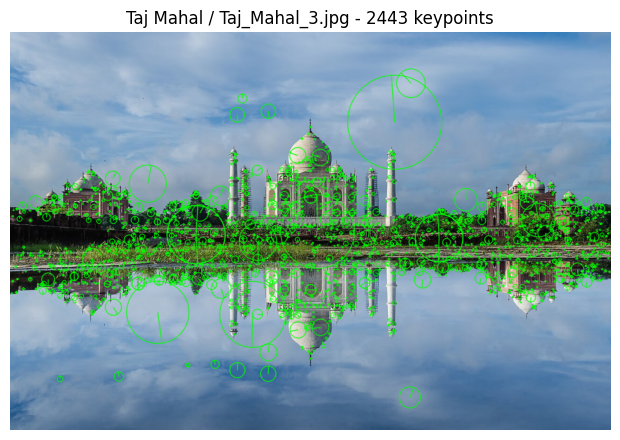

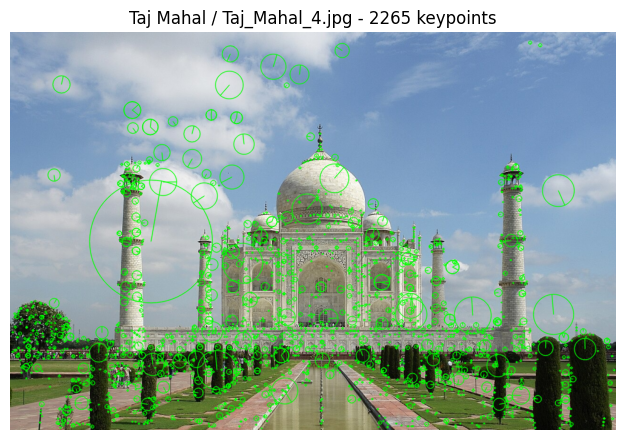

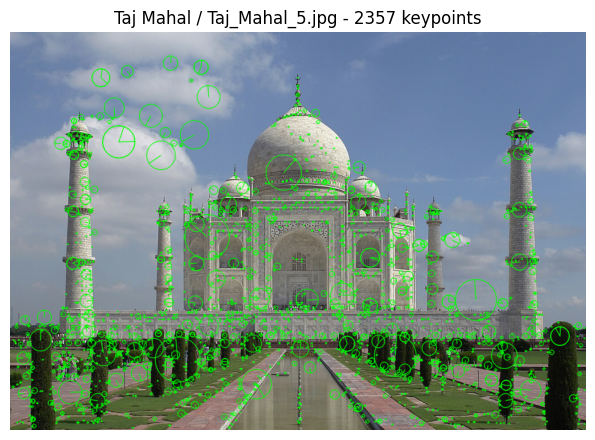

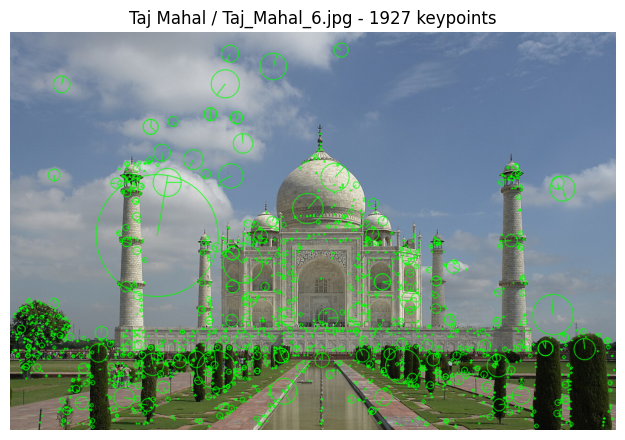


Database summary
           Landmark  Reference images  Total keypoints
          Colosseum                 6            25546
       Eiffel Tower                 6            21883
Great Wall of China                 6            29504
  Statue of Liberty                 6            12774
          Taj Mahal                 6            14906


In [7]:
db = {}
SHOW_REF_KEYPOINTS = True

for landmark in sorted(os.listdir(DB_DIR)):
    folder = os.path.join(DB_DIR, landmark)
    if not os.path.isdir(folder):
        continue
    entries = []
    for fname in sorted(os.listdir(folder)):
        if not fname.lower().endswith(IMG_EXT):
            continue
        path = os.path.join(folder, fname)
        img = load_image(path)
        kp, des = extract_sift(img)
        if des is None or len(kp) < 2:
            print("[skip]", path); continue
        if SHOW_REF_KEYPOINTS:
            show(draw_keypoints(img, kp), f"{landmark} / {fname} - {len(kp)} keypoints",
                 size=(7, 4.5), save=f"ref_kp_{landmark}_{fname}.png".replace(" ", "_"))
        entries.append({"file": path, "shape": img.shape[:2],
                        "kp": [kp_to_tuple(k) for k in kp], "des": des})
    if entries:
        db[landmark] = entries

with open("sift_database.pkl", "wb") as f:
    pickle.dump(db, f)

print("\nDatabase summary")
print(pd.DataFrame([{"Landmark": k, "Reference images": len(v),
                     "Total keypoints": sum(len(e['kp']) for e in v)} for k, v in db.items()]).to_string(index=False))
if len(db) < 5:
    print("WARNING: at least 5 landmarks are required by the assignment.")

## Task 3: Query Image Processing
Load the unknown query → grayscale → SIFT keypoints → descriptors → display keypoints.

Query: test_queries/Eiffel_Tower_1.jpg | keypoints: 3976 | descriptor shape: (3976, 128)


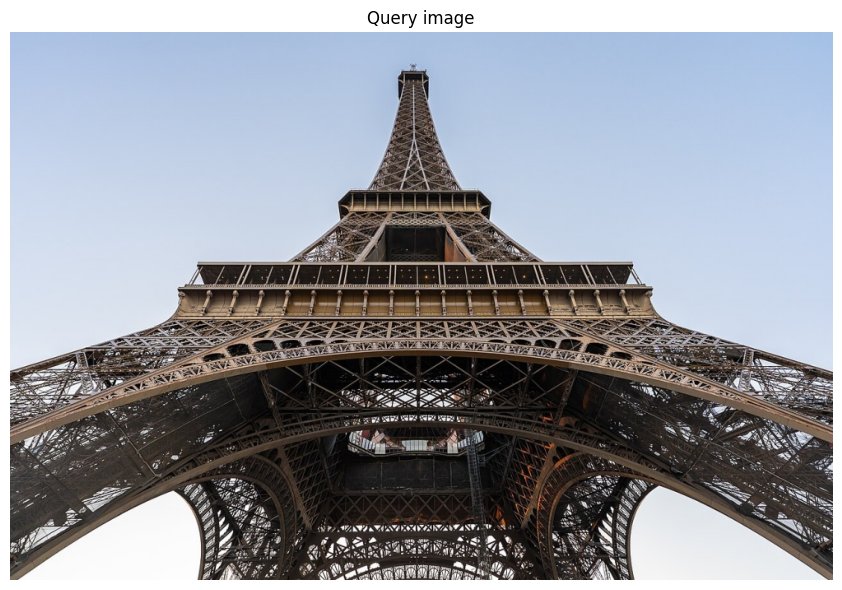

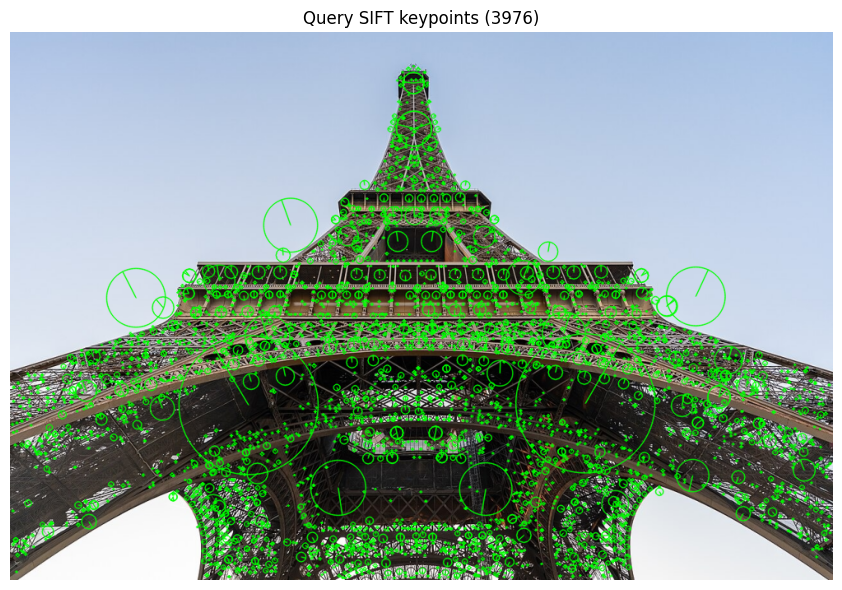

In [9]:

QUERY_PATH = "test_queries/Eiffel_Tower_1.jpg"
UPLOAD_QUERY = False

if UPLOAD_QUERY:
    from google.colab import files
    up = files.upload()
    QUERY_PATH = list(up.keys())[0]

query_img = load_image(QUERY_PATH)
kp_q, des_q = extract_sift(query_img)
print("Query:", QUERY_PATH, "| keypoints:", len(kp_q), "| descriptor shape:", des_q.shape)
show(query_img, "Query image")
show(draw_keypoints(query_img, kp_q), f"Query SIFT keypoints ({len(kp_q)})", save="query_keypoints.png")

TASK 04:

In [10]:
def ratio_matches(des_q, des_r):
    if des_q is None or des_r is None or len(des_r) < 2 or len(des_q) < 2:
        return []
    bf = cv2.BFMatcher(cv2.NORM_L2)
    knn = bf.knnMatch(des_q, des_r, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]

def rank_candidates(des_q, db):
    cands = []
    for landmark, entries in db.items():
        best = None
        for e in entries:
            good = ratio_matches(des_q, e["des"])
            if best is None or len(good) > len(best["good"]):
                best = {"landmark": landmark, "entry": e, "good": good}
        cands.append(best)
    cands.sort(key=lambda c: len(c["good"]), reverse=True)
    return cands

cands = rank_candidates(des_q, db)
rank_df = pd.DataFrame([{"Rank": i+1, "Landmark": c["landmark"], "Reliable matches": len(c["good"]),
                         "Best reference image": os.path.basename(c["entry"]["file"])}
                        for i, c in enumerate(cands)])
display(rank_df)
print("Highest raw match count:", cands[0]["landmark"], "->", len(cands[0]["good"]),
      "(final decision follows after geometric verification in Task 5)")

,Rank,Landmark,Reliable matches,Best reference image
0,1,Statue of Liberty,39,Statue_of_Liberty_5.jpg
1,2,Great Wall of China,32,Great_Wall_of_China_4.jpg
2,3,Taj Mahal,29,Taj_Mahal_4.jpg
3,4,Colosseum,25,Colosseum_3.jpg
4,5,Eiffel Tower,25,Eiffel_Tower_4.jpg


Highest raw match count: Statue of Liberty -> 39 (final decision follows after geometric verification in Task 5)


Task 5: Landmark Localization

In [11]:
def estimate_localization(kp_q, kp_r, good, ref_shape, query_shape):
    res = {"ok": False, "H": None, "mask": None, "inliers": 0, "polygon": None, "message": ""}
    if len(good) < 4:
        res["message"] = "Too few matches for homography"; return res
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None or mask is None:
        res["message"] = "Homography could not be estimated"; return res
    inl = int(mask.sum())
    res.update(H=H, mask=mask.ravel().astype(int).tolist(), inliers=inl)
    if inl < MIN_INLIERS or inl / len(good) < MIN_INLIER_RATIO:
        res["message"] = f"Geometric transformation unreliable ({inl} inliers / {len(good)} matches)"
        return res
    h, w = ref_shape
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H).reshape(-1, 2).astype(np.float32)
    qh, qw = query_shape
    area = cv2.contourArea(poly)
    if not np.all(np.isfinite(poly)):
        res["message"] = "Projected polygon invalid"
    elif not cv2.isContourConvex(poly):
        res["message"] = "Projected polygon is not convex - transformation unreliable"
    elif area < 0.005 * qh * qw or area > 4.0 * qh * qw:
        res["message"] = "Projected polygon has implausible size - transformation unreliable"
    else:
        res.update(ok=True, polygon=poly, message="Geometric verification succeeded")
    return res

## Full recognition pipeline (Tasks 3 + 4 + 5 combined) and result display

In [12]:
def recognize(img, db):
    t0 = time.perf_counter()
    kp_q, des_q = extract_sift(img)
    r = {"n_keypoints": len(kp_q), "kp_q": kp_q, "ranking": [], "predicted": "Unknown",
         "decision": "Rejected", "reason": "", "good": 0, "inliers": 0, "best": None}
    if des_q is None or len(kp_q) < 2:
        r["reason"] = "No usable SIFT features"; r["time"] = time.perf_counter() - t0; return r

    cands = rank_candidates(des_q, db)
    r["ranking"] = [(c["landmark"], len(c["good"])) for c in cands]

    verified = []
    for c in cands[:TOP_N_VERIFY]:
        if len(c["good"]) < MIN_GOOD_MATCHES:
            continue
        c["kp_r"] = [tuple_to_kp(t) for t in c["entry"]["kp"]]
        c["loc"] = estimate_localization(kp_q, c["kp_r"], c["good"], c["entry"]["shape"], img.shape[:2])
        verified.append(c)

    if len(cands[0]["good"]) < MIN_GOOD_MATCHES:
        r.update(good=len(cands[0]["good"]), best=cands[0],
                 reason=f"Best candidate has only {len(cands[0]['good'])} reliable matches (threshold {MIN_GOOD_MATCHES})")
    else:
        verified.sort(key=lambda c: c["loc"]["inliers"], reverse=True)
        top = verified[0]
        r.update(best=top, good=len(top["good"]), inliers=top["loc"]["inliers"])
        second = max([c["loc"]["inliers"] for c in verified[1:] if c["landmark"] != top["landmark"]], default=0)
        if not top["loc"]["ok"]:
            r["reason"] = top["loc"]["message"]
        elif second > 0 and top["loc"]["inliers"] < MARGIN * second:
            r["reason"] = f"Ambiguous: runner-up has {second} inliers vs {top['loc']['inliers']}"
        else:
            r.update(predicted=top["landmark"], decision="Recognized",
                     reason="Enough reliable matches + geometric verification")
    r["time"] = time.perf_counter() - t0
    return r

def render(img, r):
    out = {"keypoints": draw_keypoints(img, r["kp_q"])}
    best = r["best"]
    if best is None or len(best["good"]) == 0:
        return out
    ref = load_image(best["entry"]["file"])
    kp_r = best.get("kp_r") or [tuple_to_kp(t) for t in best["entry"]["kp"]]
    loc = best.get("loc")
    mask = loc["mask"] if loc and loc["mask"] is not None else None
    flipped = [cv2.DMatch(m.trainIdx, m.queryIdx, m.distance) for m in best["good"]]   # reference | query
    out["matches"] = cv2.drawMatches(ref, kp_r, img, r["kp_q"], flipped, None, matchColor=(0, 255, 0),
                                     matchesMask=mask, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    loc_img = img.copy()
    if loc and loc["ok"] and r["decision"] == "Recognized":
        cv2.polylines(loc_img, [np.int32(loc["polygon"])], True, (0, 0, 255), 4, cv2.LINE_AA)
        txt = f"{r['predicted']} ({r['good']} matches / {r['inliers']} inliers)"
        cv2.putText(loc_img, txt, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4)
        cv2.putText(loc_img, txt, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    else:
        msg = (loc["message"] if loc else r["reason"])[:60]
        cv2.putText(loc_img, "No reliable localization: " + msg, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    out["localization"] = loc_img
    return out

def report(img, name, save_tag=None, display_images=True):
    r = recognize(img, db)
    out = render(img, r)
    print("=" * 62)
    print(f"Query image        : {name}")
    print(f"Query keypoints    : {r['n_keypoints']}")
    print("Ranking            :", ", ".join(f"{a}={b}" for a, b in r["ranking"]))
    print(f"Predicted landmark : {r['predicted']}")
    print(f"Reliable matches   : {r['good']}")
    print(f"RANSAC inliers     : {r['inliers']}")
    print(f"Processing time    : {r['time']:.2f} s")
    print(f"STATUS             : {r['decision'].upper()}  ({r['reason']})")
    print("=" * 62)
    if display_images:
        t = save_tag
        show(img, "1. Query image", save=f"{t}_1_query.png" if t else None)
        show(out["keypoints"], f"2. Detected SIFT keypoints ({r['n_keypoints']})", save=f"{t}_2_keypoints.png" if t else None)
        if "matches" in out:
            show(out["matches"], "3. Matches: reference (left) vs query (right); green = RANSAC inliers", size=(14, 6), save=f"{t}_3_matches.png" if t else None)
        if "localization" in out:
            show(out["localization"], f"4. {r['decision']}: {r['predicted']}", save=f"{t}_4_localization.png" if t else None)
    return r

### Run the full system on the query image from Task 3
This shows all the expected outputs: query image, keypoints, matched features, predicted name, number of reliable matches, localized region and the recognized/rejected message. **Take screenshots of this output for your report.**

Query image        : test_queries/Eiffel_Tower_1.jpg
Query keypoints    : 3976
Ranking            : Statue of Liberty=39, Great Wall of China=32, Taj Mahal=29, Colosseum=25, Eiffel Tower=25
Predicted landmark : Unknown
Reliable matches   : 32
RANSAC inliers     : 6
Processing time    : 11.34 s
STATUS             : REJECTED  (Geometric transformation unreliable (6 inliers / 32 matches))


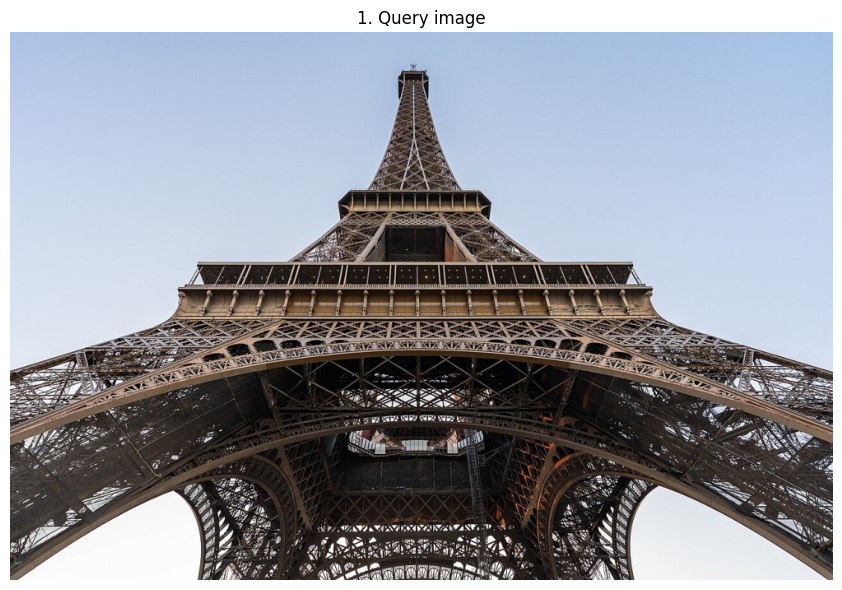

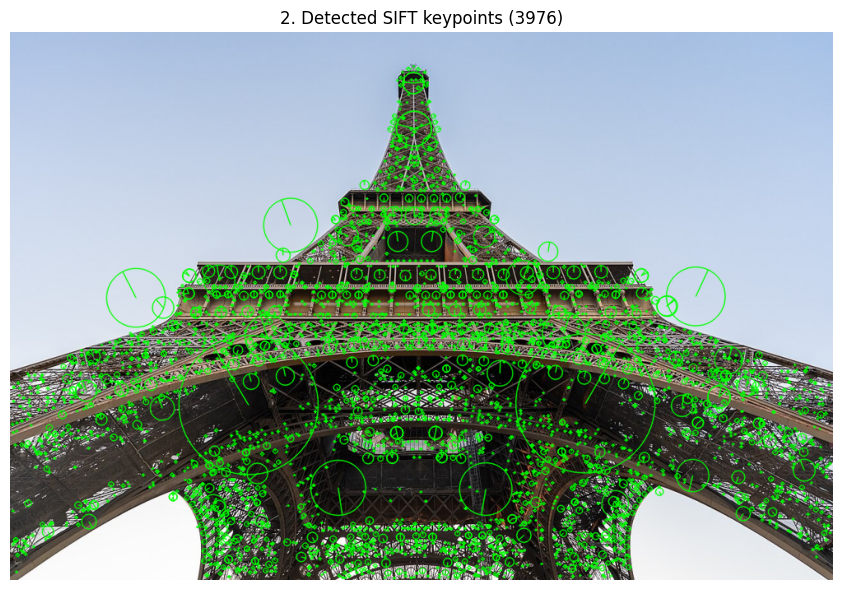

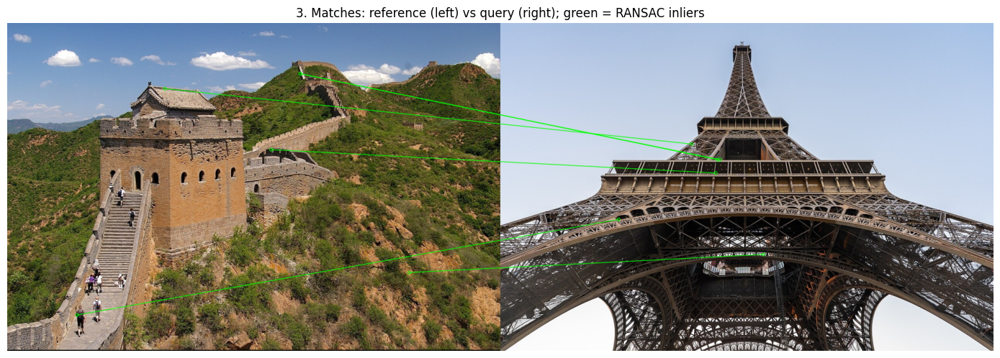

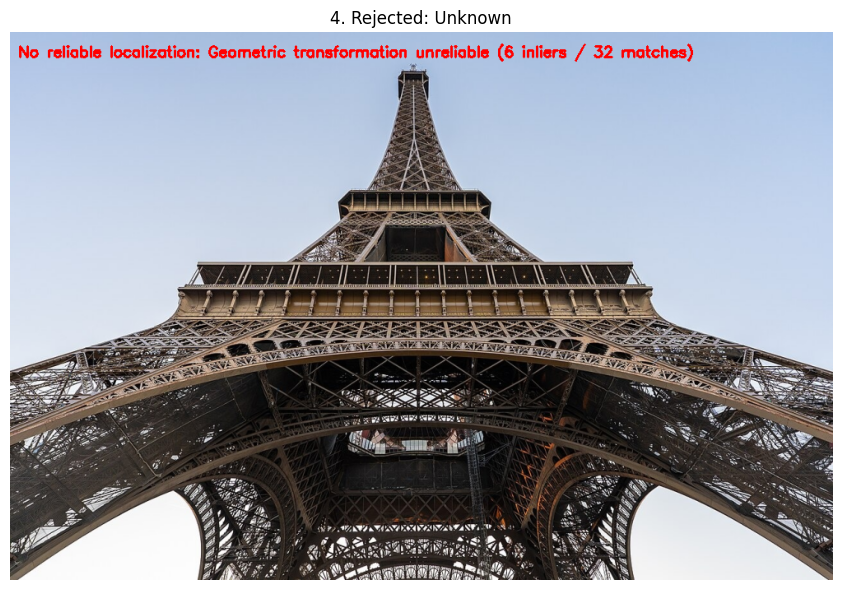

In [13]:
result = report(query_img, QUERY_PATH, save_tag="query")

## Task 6: Performance Evaluation
The test images are generated automatically from one held-out photo of a landmark (original, rotated 45°, resized 50%, brightness ×0.4). Add a **real photo from another viewpoint** and a **photo of a landmark not in the database**.

In [14]:

EVAL_QUERY     = "test_queries/Eiffel_Tower_1.jpg"
EVAL_LABEL     = "Eiffel Tower"
VIEWPOINT_PATH = "test_queries/Eiffel_Tower_2.jpg"
UNKNOWN_PATH   = "test_queries/unknown_Pyramids_of_Giza_1.jpg"
SHOW_EVAL_IMAGES = True

Query image        : Original image
Query keypoints    : 3976
Ranking            : Statue of Liberty=39, Great Wall of China=32, Taj Mahal=29, Colosseum=25, Eiffel Tower=25
Predicted landmark : Unknown
Reliable matches   : 32
RANSAC inliers     : 6
Processing time    : 10.74 s
STATUS             : REJECTED  (Geometric transformation unreliable (6 inliers / 32 matches))


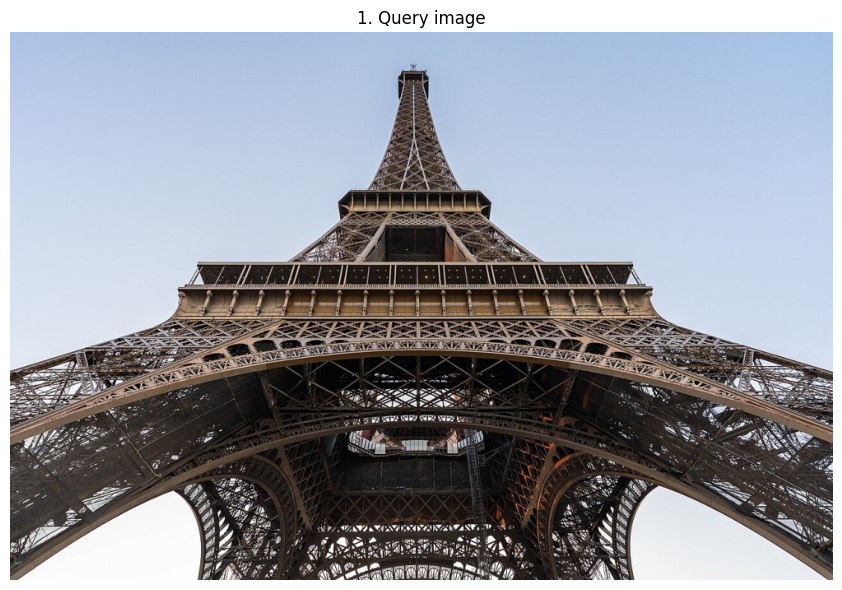

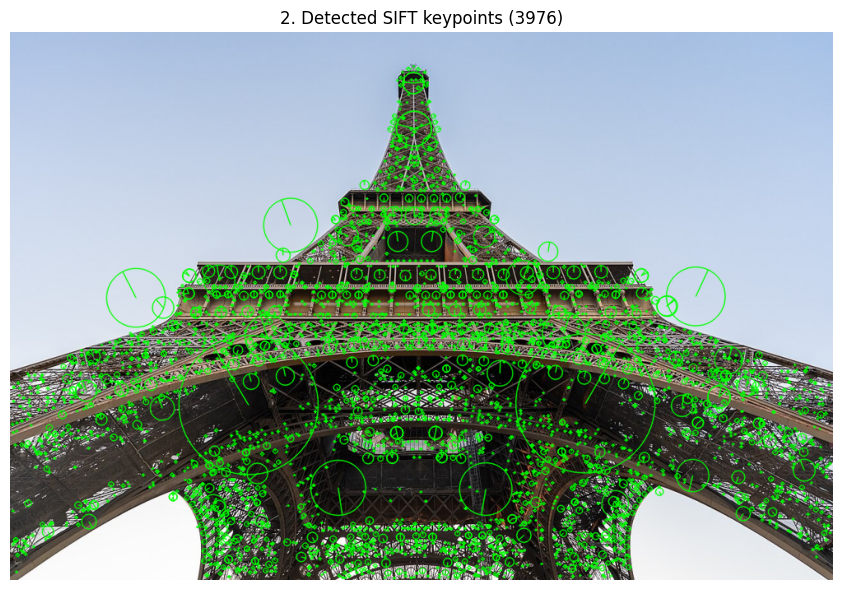

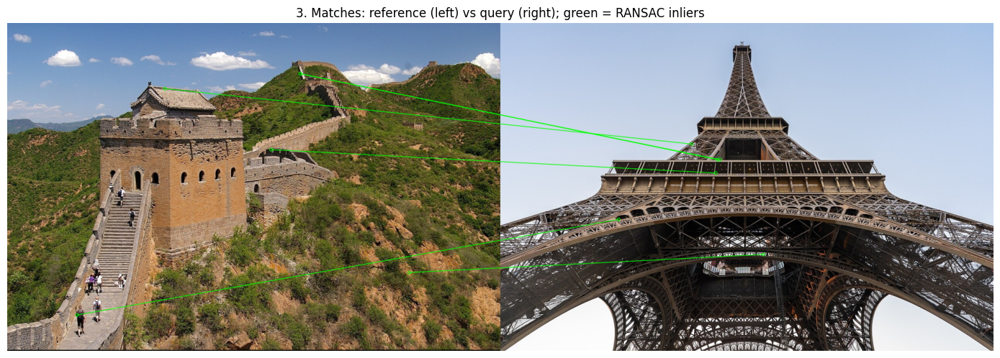

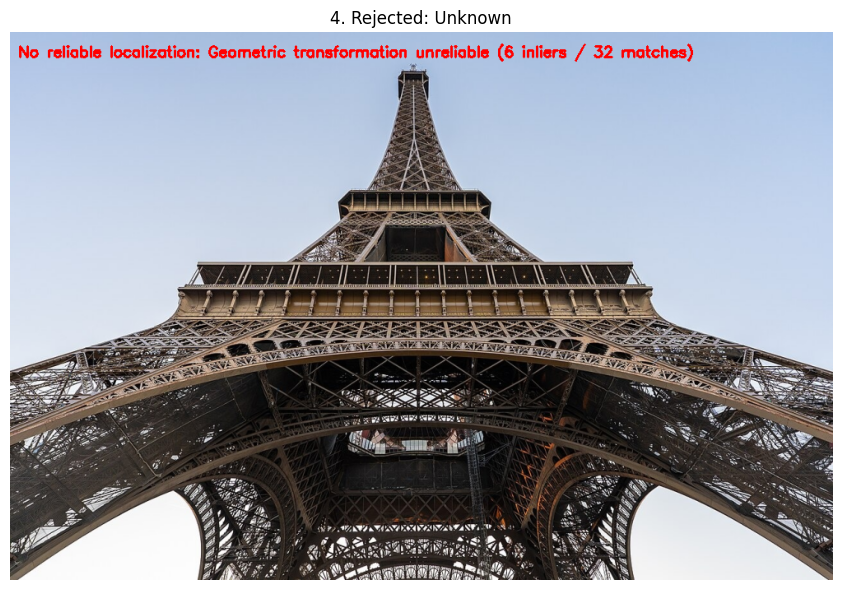

Query image        : Rotated (45 deg)
Query keypoints    : 5000
Ranking            : Statue of Liberty=54, Colosseum=51, Taj Mahal=48, Eiffel Tower=44, Great Wall of China=38
Predicted landmark : Unknown
Reliable matches   : 51
RANSAC inliers     : 6
Processing time    : 13.55 s
STATUS             : REJECTED  (Geometric transformation unreliable (6 inliers / 51 matches))


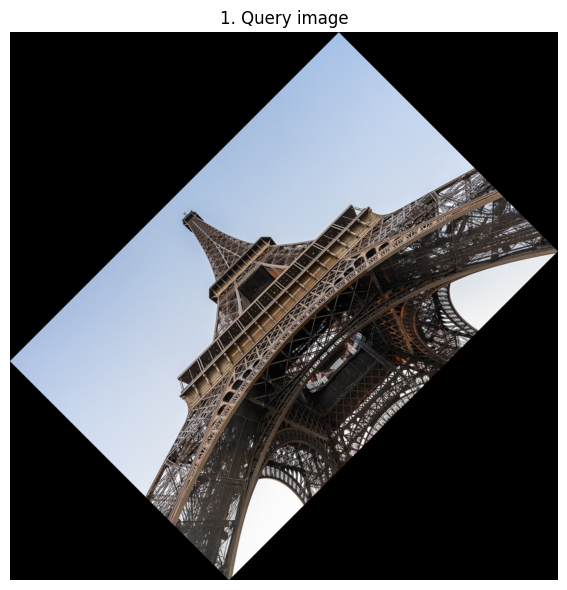

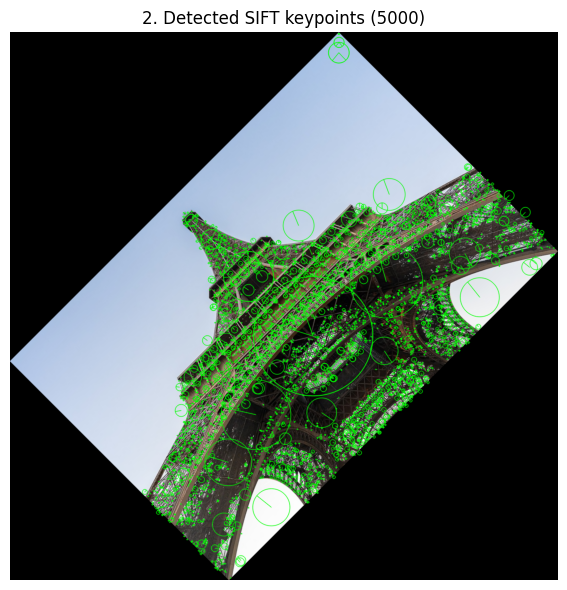

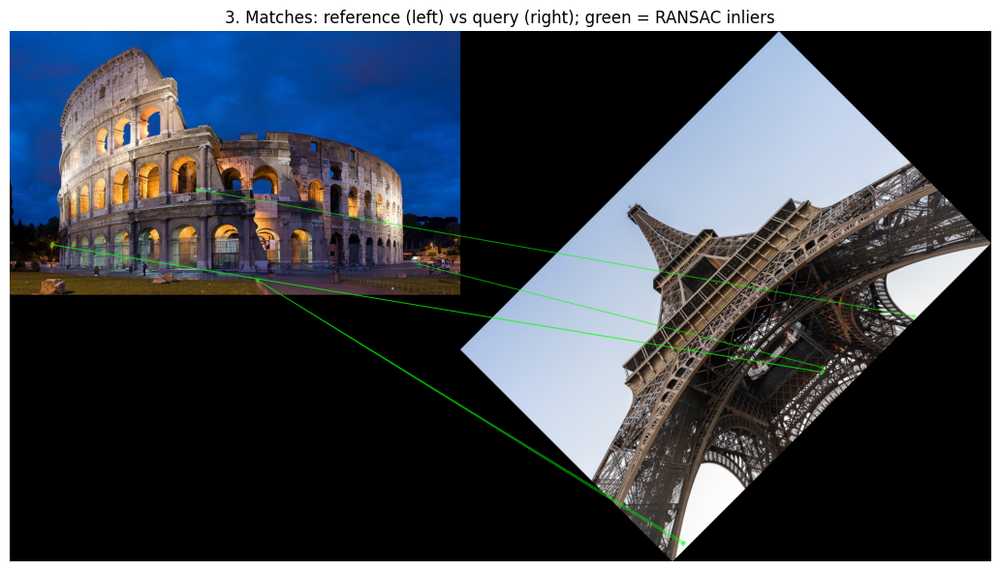

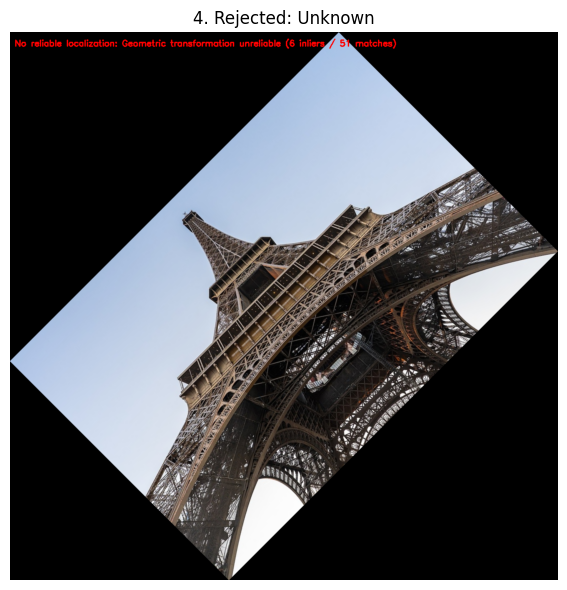

Query image        : Resized (50%)
Query keypoints    : 1075
Ranking            : Eiffel Tower=9, Great Wall of China=7, Statue of Liberty=7, Taj Mahal=6, Colosseum=3
Predicted landmark : Unknown
Reliable matches   : 9
RANSAC inliers     : 0
Processing time    : 2.86 s
STATUS             : REJECTED  (Best candidate has only 9 reliable matches (threshold 15))


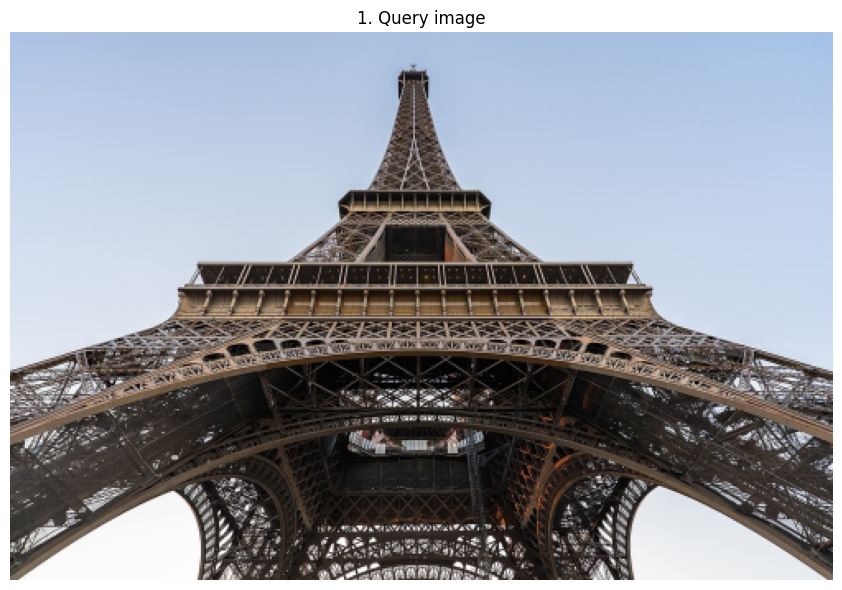

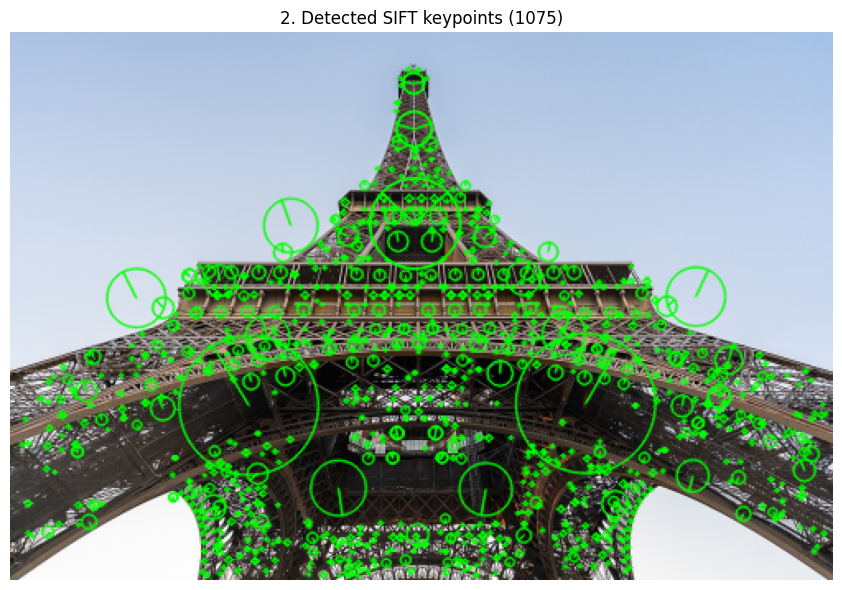

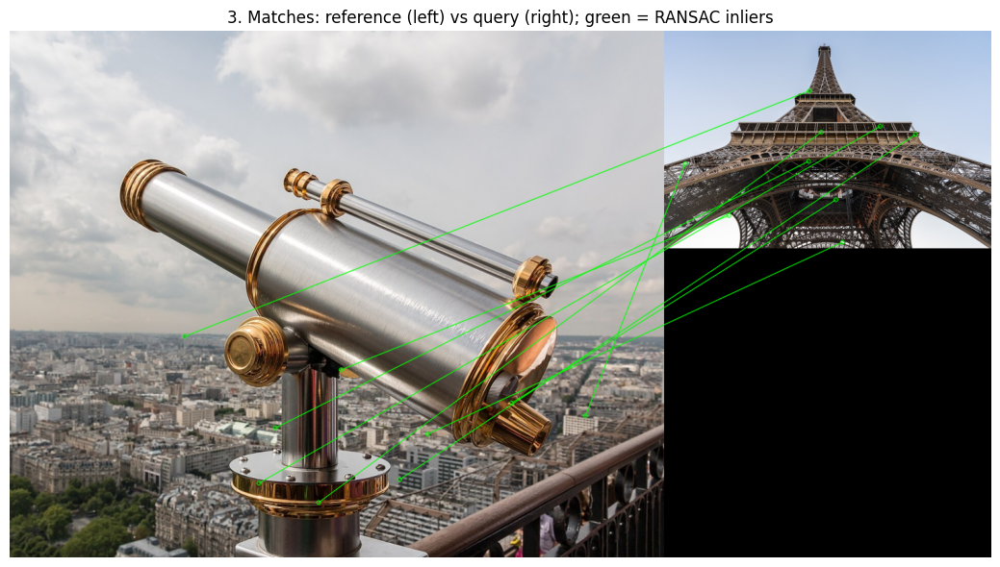

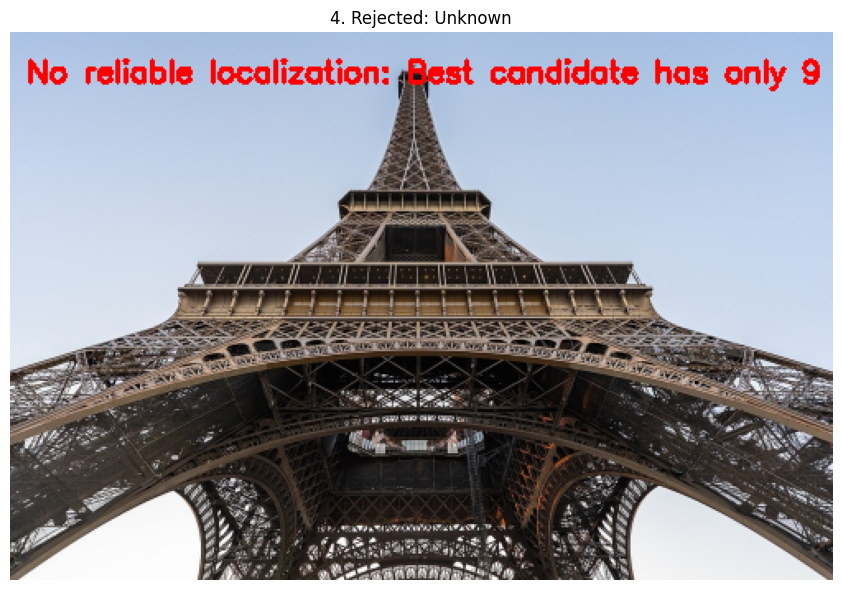

Query image        : Reduced brightness (x0.4)
Query keypoints    : 2574
Ranking            : Eiffel Tower=22, Great Wall of China=22, Statue of Liberty=22, Taj Mahal=22, Colosseum=17
Predicted landmark : Unknown
Reliable matches   : 22
RANSAC inliers     : 7
Processing time    : 7.06 s
STATUS             : REJECTED  (Geometric transformation unreliable (7 inliers / 22 matches))


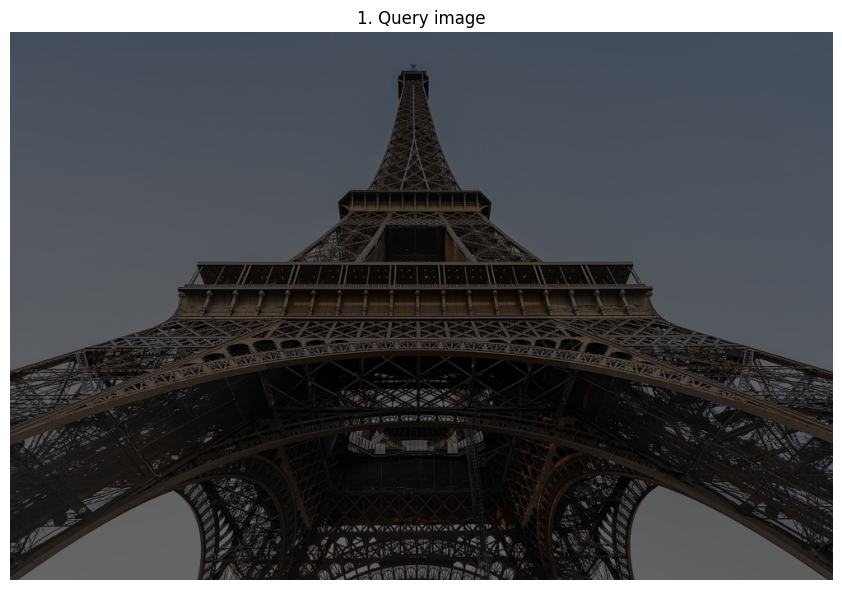

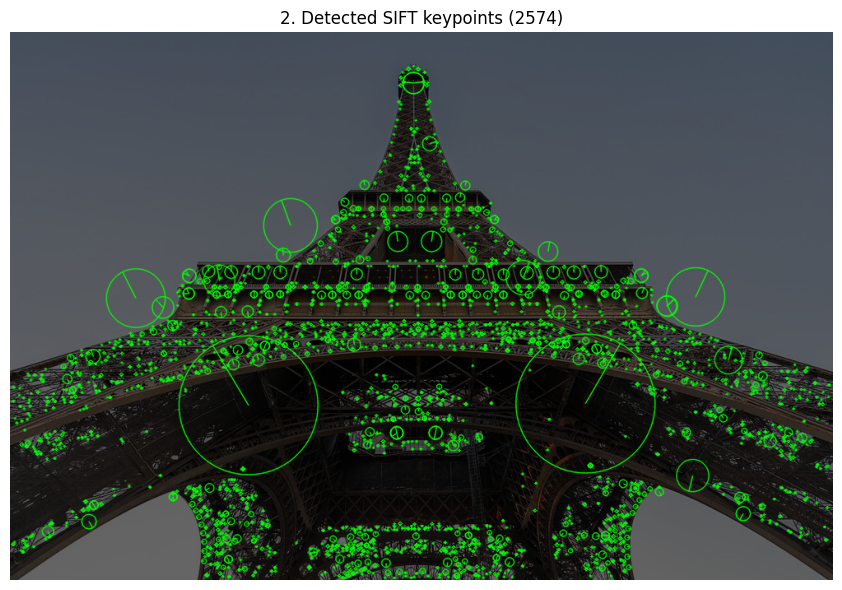

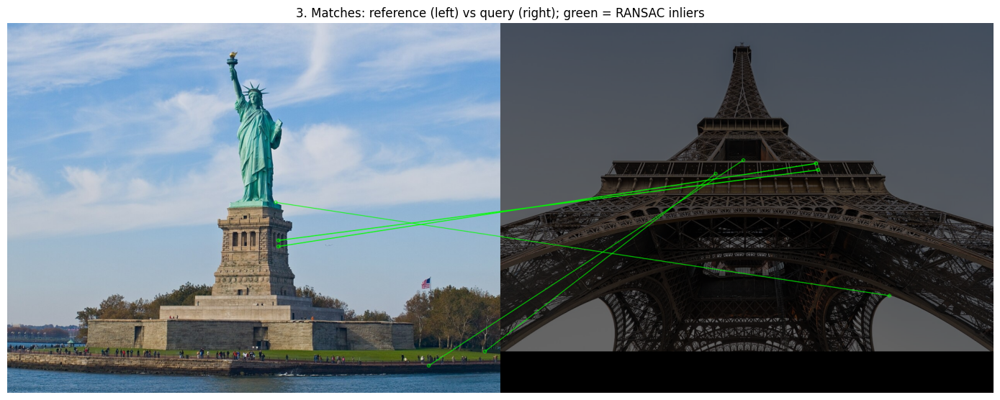

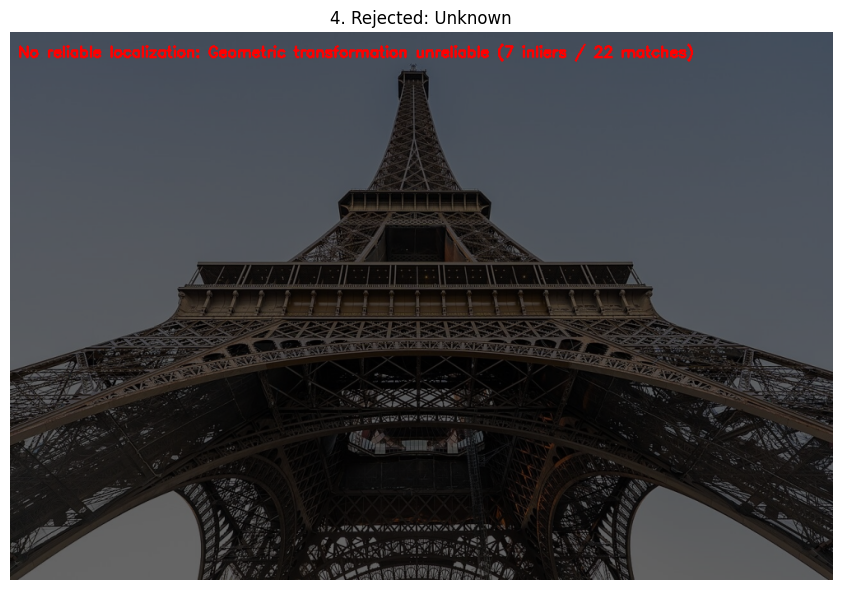

Query image        : Different viewpoint (real photo)
Query keypoints    : 2853
Ranking            : Statue of Liberty=23, Eiffel Tower=17, Great Wall of China=17, Colosseum=16, Taj Mahal=12
Predicted landmark : Unknown
Reliable matches   : 23
RANSAC inliers     : 5
Processing time    : 7.71 s
STATUS             : REJECTED  (Geometric transformation unreliable (5 inliers / 23 matches))


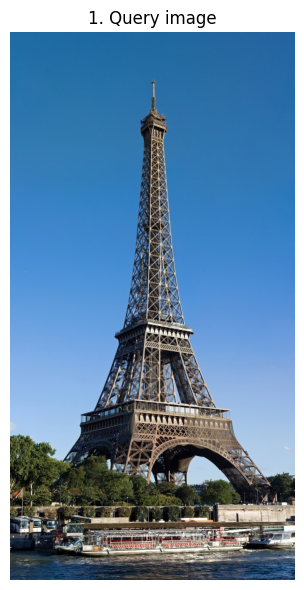

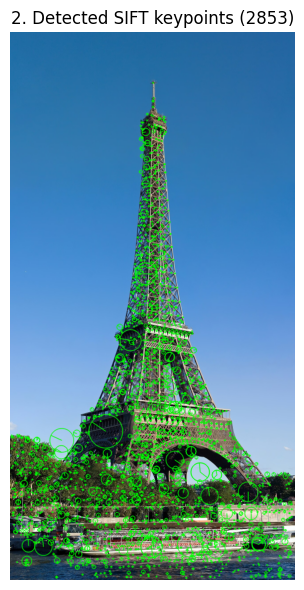

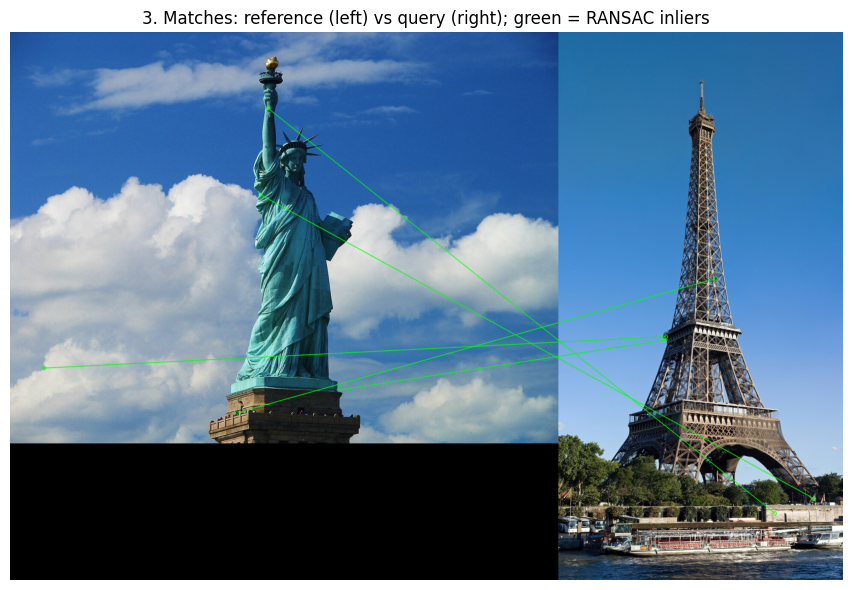

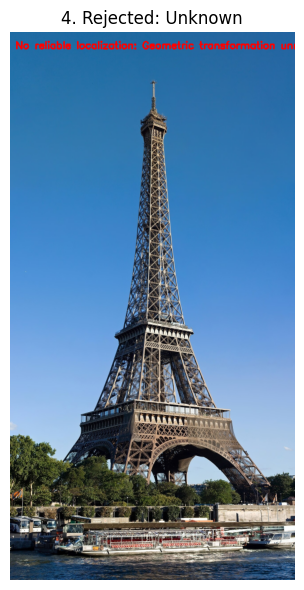

Query image        : Landmark not in database
Query keypoints    : 4260
Ranking            : Taj Mahal=24, Statue of Liberty=17, Eiffel Tower=16, Colosseum=14, Great Wall of China=14
Predicted landmark : Unknown
Reliable matches   : 24
RANSAC inliers     : 5
Processing time    : 12.12 s
STATUS             : REJECTED  (Geometric transformation unreliable (5 inliers / 24 matches))


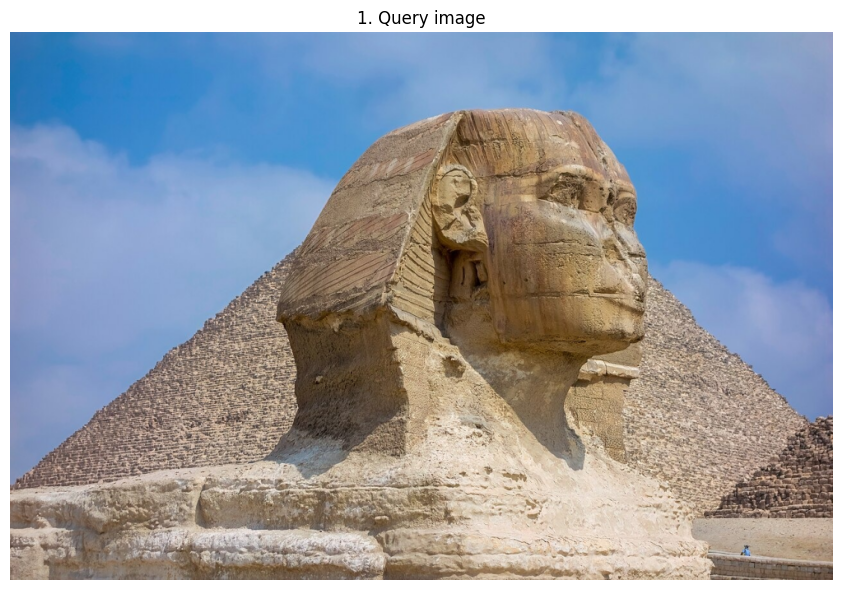

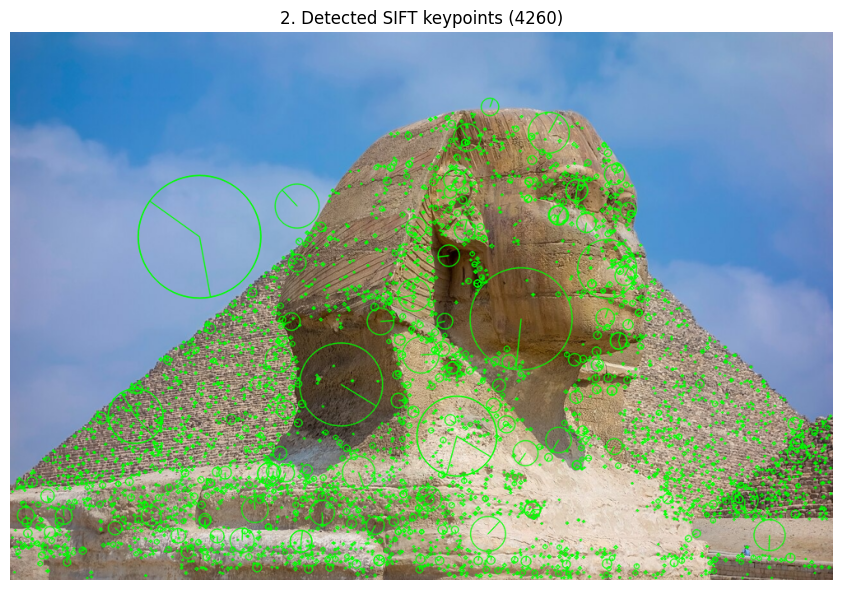

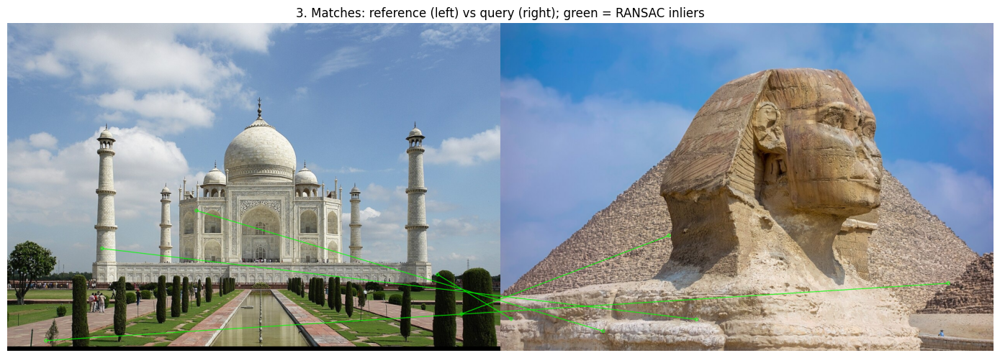

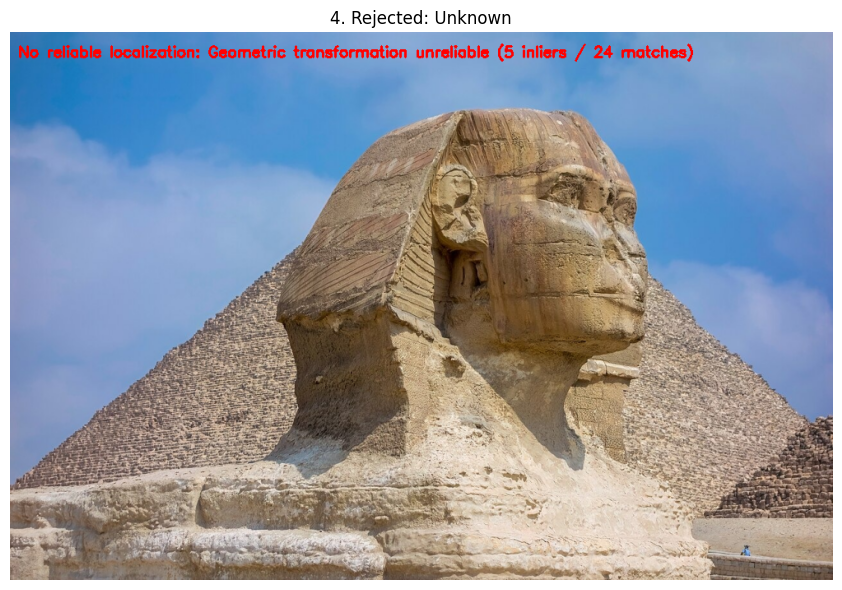


EXPERIMENTAL RESULTS


,Test condition,Expected,Predicted landmark,Keypoints,Reliable matches,RANSAC inliers,Decision,Correct,Time (s)
0,Original image,Eiffel Tower,Unknown,3976,32,6,Rejected,No,10.74
1,Rotated (45 deg),Eiffel Tower,Unknown,5000,51,6,Rejected,No,13.55
2,Resized (50%),Eiffel Tower,Unknown,1075,9,0,Rejected,No,2.86
3,Reduced brightness (x0.4),Eiffel Tower,Unknown,2574,22,7,Rejected,No,7.06
4,Different viewpoint (real photo),Eiffel Tower,Unknown,2853,23,5,Rejected,No,7.71
5,Landmark not in database,Unknown,Unknown,4260,24,5,Rejected,Yes,12.12


In [15]:
def rotate_image(img, angle=45):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h*s + w*c), int(h*c + w*s)
    M[0, 2] += nw/2 - w/2; M[1, 2] += nh/2 - h/2
    return cv2.warpAffine(img, M, (nw, nh))

def resize_image(img, f=0.5):
    return cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)

def darken_image(img, a=0.4):
    return cv2.convertScaleAbs(img, alpha=a, beta=0)

def perspective_image(img, shift=0.12):
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32([[w*shift, h*shift], [w*(1-shift/2), 0], [w*(1-shift/2), h], [w*shift, h*(1-shift)]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h))

base = load_image(EVAL_QUERY)
tests = [("Original image", base, EVAL_LABEL),
         ("Rotated (45 deg)", rotate_image(base, 45), EVAL_LABEL),
         ("Resized (50%)", resize_image(base, 0.5), EVAL_LABEL),
         ("Reduced brightness (x0.4)", darken_image(base, 0.4), EVAL_LABEL)]
if VIEWPOINT_PATH:
    tests.append(("Different viewpoint (real photo)", load_image(VIEWPOINT_PATH), EVAL_LABEL))
else:
    tests.append(("Different viewpoint (synthetic warp)", perspective_image(base), EVAL_LABEL))
if UNKNOWN_PATH:
    tests.append(("Landmark not in database", load_image(UNKNOWN_PATH), "Unknown"))
else:
    print("NOTE: set UNKNOWN_PATH to run the 'not in database' test.")

rows = []
for i, (name, img, truth) in enumerate(tests, 1):
    r = report(img, name, save_tag=f"eval{i}", display_images=SHOW_EVAL_IMAGES)
    rows.append({"Test condition": name, "Expected": truth, "Predicted landmark": r["predicted"],
                 "Keypoints": r["n_keypoints"], "Reliable matches": r["good"], "RANSAC inliers": r["inliers"],
                 "Decision": r["decision"], "Correct": "Yes" if r["predicted"] == truth else "No",
                 "Time (s)": round(r["time"], 2)})

results_df = pd.DataFrame(rows)
results_df.to_csv(os.path.join(OUT_DIR, "results_table.csv"), index=False)
print("\nEXPERIMENTAL RESULTS")
display(results_df)

## Discussion of Performance and Limitations
*(Edit this text using your own numbers from the results table above.)*

**Performance.** SIFT keypoints are scale- and rotation-invariant and descriptors are normalised, so original, rotated and resized images are expected to give many reliable matches and a high RANSAC inlier ratio. Reduced brightness lowers the number of detected keypoints (low-contrast regions are discarded) but recognition usually still succeeds. Lowe's ratio test removes ambiguous matches and RANSAC removes geometrically inconsistent ones, so an unknown landmark yields few inliers and is **rejected** instead of being assigned to the landmark with the largest raw match count. The localization polygon shows the region of the query where the reference landmark was found.

**Limitations.**
1. Large viewpoint changes break the planar-homography assumption (buildings are 3-D), reducing matches and making the polygon unreliable.
2. Repetitive structures (Colosseum arches, Great Wall bricks) create ambiguous descriptors and false matches.
3. Brute-force matching against all reference images scales linearly with database size; FLANN or bag-of-visual-words is needed for large databases.
4. Occlusion, crowds, night images or fog reduce matches. Thresholds (15 matches, 10 inliers) are empirical and trade false rejections against false acceptances.
5. A single homography gives only a rough polygon, not an exact segmentation.
6. SIFT is slower than binary descriptors such as ORB, which matters for mobile use.

**Improvements:** more reference views per landmark, CLAHE for dark images, FLANN matching, learned features (SuperPoint / LightGlue) or CNN-based retrieval.

## Download results (screenshots, CSV, database)

In [16]:
shutil.make_archive("results_package", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("results_package.zip")
    files.download("sift_database.pkl")
except ImportError:
    print("Not running in Colab: results are in the 'results' folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>